# ICS1512 — Machine Learning Algorithms Laboratory
**Sri Sivasubramaniya Nadar College of Engineering, Chennai** (An Autonomous Institution Affiliated to Anna University)

| | |
|---|---|
| **Experiment No.** | 1 |
| **Experiment Title** | Working with Python Packages: NumPy, Pandas, SciPy, Scikit-Learn, Matplotlib |
| **Student Name** | Emmanuel Maximus Ravichandran |
| **Register Number** | 3122247001015 |
| **Faculty** | Dr. Poreddy Ajay Kumar Reddy |
| **Submission Date** | |

# Objective



To explore the core functions of NumPy, Pandas, SciPy, Scikit-learn and Matplotlib; to
obtain public benchmark datasets (UCI / Kaggle) and identify the appropriate machine
learning task and model for each; and to carry out the complete machine learning workflow
(loading, exploratory data analysis, preprocessing, feature selection, data splitting and
evaluation) on five representative datasets.

# Problem Statement



Given five benchmark datasets (Iris, Loan Amount Prediction, Predicting Diabetes, Email Spam
Classification and Handwritten Character Recognition / MNIST), determine for each whether
the problem is classification or regression, apply a suitable feature selection technique
and baseline algorithm, and evaluate it with appropriate metrics. The findings are tabulated
in the summary table at the end of the report.

# Dataset Description




| Dataset | Source | Samples | Features | Target |
|---|---|---|---|---|
| Iris | scikit-learn (UCI) | 150 | 4 | species (3 classes) |
| Loan Amount Prediction | Kaggle | 30000 | 20 (after dropping ID, name and property ID) | Loan Sanction Amount (USD) |
| Predicting Diabetes | scikit-learn (diabetes progression) | 442 | 10 | median split of progression (2 classes) |
| Email Spam | UCI Spambase | 4601 | 57 | spam / non-spam |
| Handwritten Digits (MNIST-style) | scikit-learn (UCI optical digits) | 1797 | 64 (8x8 pixels) | digit 0-9 (10 classes) |


Iris, Diabetes and the 8x8 handwritten digits are bundled with scikit-learn. The Loan Amount
and Spambase datasets were downloaded from Kaggle / the UCI repository and are read from the
local `data/` folder (`loan_train.csv`, `spambase.data`, `spambase.names`). The full 28x28
MNIST dataset is represented by the 8x8 UCI optical digits, a lightweight dataset of the
same task type.

# Setup and Library Exploration

## Setup and Imports




A hidden setup block defines two small helpers that appear at the end of the figure and
table cells below: _fig() closes the Matplotlib figure and returns its caption and image
link to Org, and _tbl() turns a DataFrame into a captioned Org table, so that figures and
tables regenerate with the report each time the file is executed.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import sklearn
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
os.makedirs("figures", exist_ok=True)
sns.set_style("whitegrid")
print("NumPy       :", np.__version__)
print("Pandas      :", pd.__version__)
print("SciPy       :", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib  :", matplotlib.__version__)

NumPy       : 2.4.4
Pandas      : 3.0.2
SciPy       : 1.17.1
Scikit-learn: 1.8.0
Matplotlib  : 3.10.8


**Inference:** All five libraries import cleanly (NumPy 2.4.4, Pandas 3.0.2, SciPy 1.17.1, scikit-learn
1.8.0, Matplotlib 3.10.8). Recording the versions makes the results reproducible, since
defaults such as the Pandas string dtype and SciPy's mode output change between releases.

## Part 1: NumPy, Array Manipulation and Numerical Computing

In [2]:
a = np.array([1, 2, 3, 4, 5])
zeros = np.zeros((2, 3))
ones = np.ones((3, 3))
arange_arr = np.arange(0, 10, 2)
lin_arr = np.linspace(0, 1, 5)
identity = np.eye(3)
print("a          :", a)
print("zeros      :\n", zeros)
print("ones       :\n", ones)
print("arange     :", arange_arr)
print("linspace   :", lin_arr)
print("identity   :\n", identity)

a          : [1 2 3 4 5]
zeros      :
 [[0. 0. 0.]
 [0. 0. 0.]]
ones       :
 [[1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]]
arange     : [0 2 4 6 8]
linspace   : [0.   0.25 0.5  0.75 1.  ]
identity   :
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


**Inference:** The creation routines cover the common cases: zeros and ones for initialisation, arange for
a step-based range, linspace for a fixed number of evenly spaced points (0, 0.25, 0.5, 0.75,
1.0) and eye for the identity matrix. Note that arange(0, 10, 2) excludes the stop value,
whereas linspace includes it.

In [3]:
print("Shape:", a.shape, "| Ndim:", a.ndim, "| Dtype:", a.dtype)
print("First 3:", a[:3], "| Reversed:", a[::-1])
mat = np.arange(12).reshape(3, 4)
print("Reshaped 3x4:\n", mat)
print("Row 1:", mat[1, :], "| Column 2:", mat[:, 2])

Shape: (5,) | Ndim: 1 | Dtype: int64
First 3: [1 2 3] | Reversed: [5 4 3 2 1]
Reshaped 3x4:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
Row 1: [4 5 6 7] | Column 2: [ 2  6 10]


**Inference:** The array has shape (5,), one dimension and dtype int64. Slicing with a[::-1] reverses it
without copying data, and reshape turned the 12 values from arange into a 3x4 matrix. mat[1,
:] selects a row and mat[:, 2] a column, which is the basic pattern for selecting samples
and features in a data matrix.

In [4]:
print("Sum:", a.sum(), "| Mean:", a.mean(), "| Std:", a.std(), "| Var:", a.var())
print("Max/Min:", a.max(), a.min(), "| Argmax/Argmin:", a.argmax(), a.argmin())
print("Cumulative sum:", a.cumsum())
print("a * 2       :", a * 2)
print("a + [10..50]:", a + np.array([10, 20, 30, 40, 50]))
m1 = np.array([[1, 2], [3, 4]])
m2 = np.array([[5, 6], [7, 8]])
print("Matrix product:\n", np.dot(m1, m2))
print("Transpose:\n", m1.T)
print("Determinant:", np.linalg.det(m1))
print("Inverse:\n", np.linalg.inv(m1))

Sum: 15 | Mean: 3.0 | Std: 1.4142135623730951 | Var: 2.0
Max/Min: 5 1 | Argmax/Argmin: 4 0
Cumulative sum: [ 1  3  6 10 15]
a * 2       : [ 2  4  6  8 10]
a + [10..50]: [11 22 33 44 55]
Matrix product:
 [[19 22]
 [43 50]]
Transpose:
 [[1 3]
 [2 4]]
Determinant: -2.0000000000000004
Inverse:
 [[-2.   1. ]
 [ 1.5 -0.5]]


**Inference:** The statistics match hand calculation: sum 15, mean 3.0 and variance 2.0 (population
variance, because NumPy uses ddof=0 by default). The product of the two 2x2 matrices is
[[19, 22], [43, 50]], and the determinant of -2 is non-zero, so the matrix is invertible.
The inverse [[-2, 1], [1.5, -0.5]] therefore exists. Broadcasting added a scalar and a same-
length vector without any loops.

In [5]:
mask = a > 2
print("Elements > 2:", a[mask])
print("Sorted (desc):", np.sort(a)[::-1])
rng = np.random.default_rng(42)
rand_arr = rng.random((3, 3))
print("Random 3x3 array:\n", rand_arr)

Elements > 2: [3 4 5]
Sorted (desc): [5 4 3 2 1]
Random 3x3 array:
 [[0.77395605 0.43887844 0.85859792]
 [0.69736803 0.09417735 0.97562235]
 [0.7611397  0.78606431 0.12811363]]


**Inference:** A boolean mask returned exactly the elements greater than 2 ([3 4 5]). Seeding the generator
with default_rng(42) makes the random 3x3 array repeatable, which is required for
reproducible train/test splits later in the experiment.

## Part 2: Pandas, Data Handling

In [6]:
s = pd.Series([10, 20, 30, 40], index=["a", "b", "c", "d"])
print("Series:\n", s)
df = pd.DataFrame({
    "Name": ["Asha", "Ravi", "Meera", "Kabir"],
    "Age": [21, 22, 20, 23],
    "Marks": [88, 76, 95, 67]
})
print("\nDataFrame:\n", df)

Series:
 a    10
b    20
c    30
d    40
dtype: int64

DataFrame:
     Name  Age  Marks
0   Asha   21     88
1   Ravi   22     76
2  Meera   20     95
3  Kabir   23     67


**Inference:** The Series carries a custom index (a to d), while the DataFrame stores heterogeneous columns
(a string Name and integer Age and Marks) in one labelled table. This is the structure used
for every dataset that follows.

In [7]:
df.info()
print("\n", df.describe())
print("\nColumn 'Age':\n", df["Age"])
print("\nRows where Marks > 80:\n", df[df["Marks"] > 80])

<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Name    4 non-null      str  
 1   Age     4 non-null      int64
 2   Marks   4 non-null      int64
dtypes: int64(2), str(1)
memory usage: 228.0 bytes

              Age    Marks
count   4.000000   4.0000
mean   21.500000  81.5000
std     1.290994  12.4499
min    20.000000  67.0000
25%    20.750000  73.7500
50%    21.500000  82.0000
75%    22.250000  89.7500
max    23.000000  95.0000

Column 'Age':
 0    21
1    22
2    20
3    23
Name: Age, dtype: int64

Rows where Marks > 80:
     Name  Age  Marks
0   Asha   21     88
2  Meera   20     95


**Inference:** info() confirms four non-null rows and the column dtypes, and describe() gives the mean
marks as 81.5 with a standard deviation of 12.45. Boolean filtering on Marks > 80 selected
Asha (88) and Meera (95).

In [8]:
df2 = df.copy()
df2.loc[1, "Marks"] = np.nan
print("With missing value:\n", df2)
print("\nAfter fillna(mean):\n", df2.fillna(df2["Marks"].mean()))
df["Result"] = np.where(df["Marks"] >= 80, "Pass", "Fail")
print("\nGroup by pass/fail:")
print(df.groupby("Result")["Marks"].mean())

With missing value:
     Name  Age  Marks
0   Asha   21   88.0
1   Ravi   22    NaN
2  Meera   20   95.0
3  Kabir   23   67.0

After fillna(mean):
     Name  Age      Marks
0   Asha   21  88.000000
1   Ravi   22  83.333333
2  Meera   20  95.000000
3  Kabir   23  67.000000

Group by pass/fail:
Result
Fail    71.5
Pass    91.5
Name: Marks, dtype: float64


**Inference:** After one value was set to NaN, fillna with the column mean (83.33) restored a complete
column. Mean imputation is the simplest strategy and is reused later through SimpleImputer.
Grouping by Pass/Fail gave mean marks of 91.5 for Pass and 71.5 for Fail.

## Part 3: SciPy, Scientific and Statistical Computing

In [9]:
data = np.array([12, 15, 14, 10, 18, 20, 22, 14, 15, 16])
print("Mean:", np.mean(data), "| Median:", np.median(data))
print("Mode:", stats.mode(data, keepdims=True))
print("Skewness:", stats.skew(data), "| Kurtosis:", stats.kurtosis(data))
t_stat, p_val = stats.ttest_1samp(data, popmean=15)
print(f"\nOne-sample t-test vs mean=15: t={t_stat:.3f}, p={p_val:.3f}")

Mean: 15.6 | Median: 15.0
Mode: ModeResult(mode=array([14]), count=array([2]))
Skewness: 0.32815694566595727 | Kurtosis: -0.6009140184929325

One-sample t-test vs mean=15: t=0.528, p=0.611


**Inference:** The sample has mean 15.6 and median 15.0, a mode of 14 (occurring twice), mild positive
skewness (0.33) and negative excess kurtosis (-0.60), so it is slightly right-skewed and
flatter than a normal curve. The one-sample t-test against a mean of 15 gave t = 0.528 and p
= 0.611. Since p is far above 0.05 we cannot reject the hypothesis that the population mean
is 15.

In [10]:
from scipy import special, linalg
print("Gamma(5):", special.gamma(5))
print("Factorial(5) via special.factorial:", special.factorial(5))
A = np.array([[3, 1], [1, 2]])
b = np.array([9, 8])
x = linalg.solve(A, b)
print("\nSolution of Ax=b:", x)
print("Eigenvalues of A:", linalg.eigvals(A))

Gamma(5): 24.0
Factorial(5) via special.factorial: 120.0



Solution of Ax=b: [2. 3.]
Eigenvalues of A: [3.61803399+0.j 1.38196601+0.j]


**Inference:** special.gamma(5) returned 24, which equals 4!, and special.factorial(5) returned 120.
linalg.solve found x = [2, 3] for the system Ax = b, and the eigenvalues of A (3.618 and
1.382) are both positive and real, so A is positive definite.

## Part 4: Matplotlib, Data Visualization

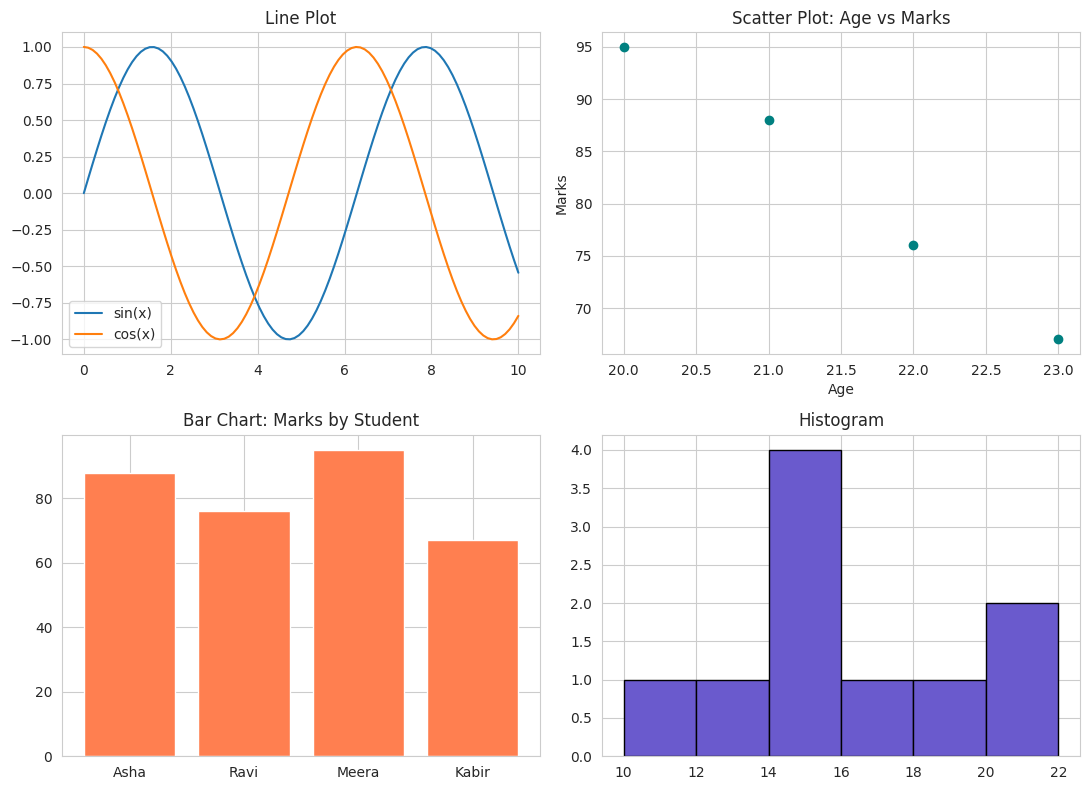

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
x = np.linspace(0, 10, 100)
axes[0, 0].plot(x, np.sin(x), label="sin(x)")
axes[0, 0].plot(x, np.cos(x), label="cos(x)")
axes[0, 0].set_title("Line Plot")
axes[0, 0].legend()
axes[0, 1].scatter(df["Age"], df["Marks"], c="teal")
axes[0, 1].set_title("Scatter Plot: Age vs Marks")
axes[0, 1].set_xlabel("Age"); axes[0, 1].set_ylabel("Marks")
axes[1, 0].bar(df["Name"], df["Marks"], color="coral")
axes[1, 0].set_title("Bar Chart: Marks by Student")
axes[1, 1].hist(data, bins=6, color="slateblue", edgecolor="black")
axes[1, 1].set_title("Histogram")
plt.tight_layout()
plt.savefig("figures/fig_01_matplotlib.png", dpi=110, bbox_inches="tight")
plt.show()

**Inference:** The 2x2 grid shows the four basic plot types used in EDA: a line plot of sin and cos for
trends, a scatter plot for the relationship between two variables, a bar chart for comparing
categories and a histogram for the distribution of a single variable. The subplots share one
figure, which keeps related views side by side.

## Part 5: Scikit-learn, Core API Tour

In [12]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, mean_absolute_error, mean_squared_error, r2_score
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
clf = LogisticRegression(max_iter=200).fit(X_train_s, y_train)
pred = clf.predict(X_test_s)
print("Accuracy:", accuracy_score(y_test, pred))
print(classification_report(y_test, pred, target_names=iris.target_names))

Accuracy: 0.9333333333333333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



**Inference:** The standard fit/predict workflow on Iris with scaled features and logistic regression gave
93.3% accuracy on 30 test flowers. Setosa was classified perfectly, while versicolor and
virginica each scored 0.90 precision and recall, which matches the known overlap between
those two species. The scaler was fitted on the training split only, so no test information
leaked into training.

# Dataset Exploration and ML Task Identification



For each of the five datasets the workflow is: load the data, identify the ML task, perform
EDA, preprocess, select features, split into training / validation / testing sets and
evaluate a baseline model.

## Iris Dataset: Multi-class Classification (Supervised)

In [13]:
iris = load_iris(as_frame=True)
iris_df = iris.frame
iris_df["species"] = iris_df["target"].map(dict(enumerate(iris.target_names)))
print(iris_df.head())
print("\nShape:", iris_df.shape)
print("\nMissing values:\n", iris_df.isna().sum())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target species  
0       0  setosa  
1       0  setosa  
2       0  setosa  
3       0  setosa  
4       0  setosa  

Shape: (150, 6)

Missing values:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64


**Inference:** Iris has 150 rows and 4 numeric features plus the target, with no missing values, so no
imputation is needed. It is a labelled problem with three discrete classes, which makes it a
supervised multi-class classification task.

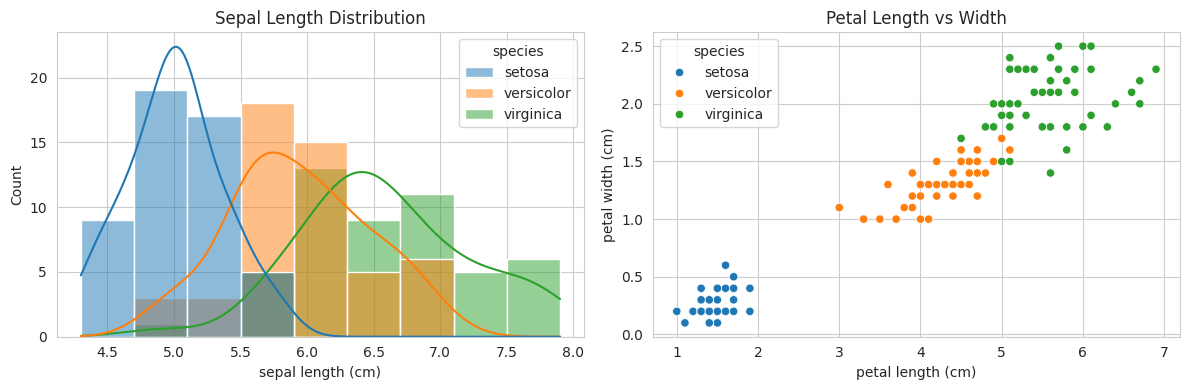

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=iris_df, x="sepal length (cm)", hue="species", kde=True, ax=axes[0])
axes[0].set_title("Sepal Length Distribution")
sns.scatterplot(data=iris_df, x="petal length (cm)", y="petal width (cm)", hue="species", ax=axes[1])
axes[1].set_title("Petal Length vs Width")
plt.tight_layout()
plt.savefig("figures/fig_02_iris_eda.png", dpi=110, bbox_inches="tight")
plt.show()

**Inference:** Sepal length overlaps heavily between versicolor and virginica, so it separates the species
only partially. In the scatter plot of petal length against petal width, setosa forms a
completely separate cluster and versicolor and virginica are almost separable, which shows
that the petal measurements carry most of the class information.

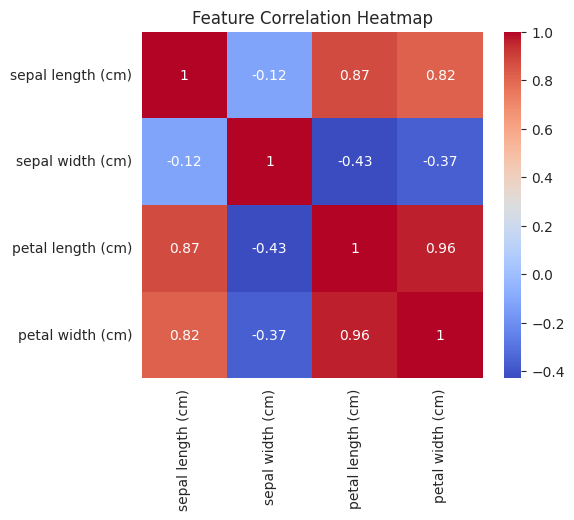

In [15]:
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(iris_df.iloc[:, :4].corr(), annot=True, cmap="coolwarm")
plt.title("Feature Correlation Heatmap")
plt.savefig("figures/fig_03_iris_corr.png", dpi=110, bbox_inches="tight")
plt.show()

**Inference:** Petal length and petal width are very strongly correlated (0.96), and both correlate
strongly with sepal length (0.87 and 0.82). Sepal width is the only feature with a negative
correlation to the others. The high collinearity means that two features may carry nearly
the same information as four.

In [16]:
from sklearn.feature_selection import SelectKBest, f_classif, chi2
X_iris, y_iris = iris.data, iris.target
selector = SelectKBest(score_func=f_classif, k=2).fit(X_iris, y_iris)
scores = pd.Series(selector.scores_, index=X_iris.columns).sort_values(ascending=False)
print("ANOVA F-scores:\n", scores)
print("\nTop 2 selected features:", X_iris.columns[selector.get_support()].tolist())

ANOVA F-scores:
 petal length (cm)    1180.161182
petal width (cm)      960.007147
sepal length (cm)     119.264502
sepal width (cm)       49.160040
dtype: float64

Top 2 selected features: ['petal length (cm)', 'petal width (cm)']


**Inference:** The ANOVA F-test ranks petal length (F = 1180) and petal width (F = 960) far above sepal
length (119) and sepal width (49). SelectKBest with k = 2 therefore keeps the two petal
features, which agrees with what the scatter plot and correlation heatmap suggested.

In [17]:
Xtmp, Xte, ytmp, yte = train_test_split(X_iris, y_iris, test_size=0.2, random_state=42, stratify=y_iris)
Xtr, Xval, ytr, yval = train_test_split(Xtmp, ytmp, test_size=0.25, random_state=42, stratify=ytmp)
print("Train / Validation / Test sizes:", len(Xtr), len(Xval), len(Xte))
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier(max_depth=3, random_state=42).fit(Xtr, ytr)
print("Validation accuracy:", accuracy_score(yval, model.predict(Xval)))
pred = model.predict(Xte)
print("Test accuracy      :", accuracy_score(yte, pred))

Train / Validation / Test sizes: 90 30 30
Validation accuracy: 0.9
Test accuracy      : 0.9333333333333333


**Inference:** The data was split 60/20/20 into 90 training, 30 validation and 30 test samples, stratified
so every class keeps the same proportion. A depth-3 decision tree scored 0.90 on validation
and 0.933 on test. The validation set is what would be used to tune settings such as
max_depth, so that the test set stays untouched until the final evaluation. With only 30
samples per split, one sample changes accuracy by 3.3 percentage points, so these figures
are noisy.

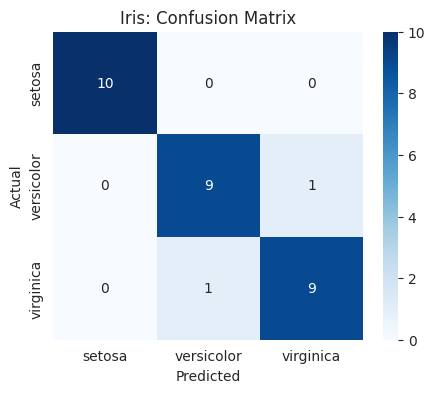

In [18]:
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(yte, pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.title("Iris: Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.savefig("figures/fig_04_iris_cm.png", dpi=110, bbox_inches="tight")
plt.show()

**Inference:** The tree classified all 10 setosa flowers correctly and made one error each for versicolor
and virginica (one of each was predicted as the other), giving 28 of 30 correct. This again
shows that all errors lie on the versicolor/virginica boundary.

## Loan Amount Prediction: Regression (Supervised)



The Kaggle Loan Amount dataset (30000 applicants) contains numeric and categorical applicant
attributes. The target is the loan amount sanctioned. The raw file uses -999 as a
placeholder for invalid values and contains many missing entries, so both are handled during
preprocessing.

In [19]:
loan_raw = pd.read_csv("data/loan_train.csv")
print("Shape:", loan_raw.shape)
miss = loan_raw.isna().sum()
print("\nColumns with missing values:\n", miss[miss > 0])
num = loan_raw.select_dtypes("number")
sent = (num == -999).sum()
print("\nColumns containing the -999 placeholder:\n", sent[sent > 0])

Shape: (30000, 24)

Columns with missing values:
 Gender                           53
Income (USD)                   4576
Income Stability               1683
Type of Employment             7270
Current Loan Expenses (USD)     172
Dependents                     2493
Credit Score                   1703
Has Active Credit Card         1566
Property Age                   4850
Property Location               356
Loan Sanction Amount (USD)      340
dtype: int64

Columns containing the -999 placeholder:
 Current Loan Expenses (USD)    177
Co-Applicant                   168
Property Price                 352
Loan Sanction Amount (USD)     338
dtype: int64


**Inference:** The loan file has 30000 rows and 24 columns. Eleven columns contain missing values, with
Type of Employment (7270), Property Age (4850), Income (4576) and Dependents (2493) the
worst affected. Four numeric columns, including the target, also contain -999, which is a
placeholder for invalid entries and not a real amount. If left in place it would distort the
scaling and the regression.

In [20]:
loan = loan_raw.drop(columns=["Customer ID", "Name", "Property ID"]).copy()
loan = loan.replace(-999, np.nan)
target = "Loan Sanction Amount (USD)"
loan = loan.dropna(subset=[target])
print("Rows after dropping missing/invalid target:", len(loan))
print("Rows with a sanctioned amount of zero (loan not granted):", int((loan[target] == 0).sum()))
print(loan[target].describe().round(2))

Rows after dropping missing/invalid target: 29322
Rows with a sanctioned amount of zero (loan not granted): 7865
count     29322.00
mean      48210.12
std       48212.94
min           0.00
25%           0.00
50%       36064.22
75%       74779.28
max      481907.32
Name: Loan Sanction Amount (USD), dtype: float64


**Inference:** The customer ID, name and property ID carry no predictive information, so they were dropped.
After converting -999 to NaN and removing the 678 rows with a missing or invalid target,
29322 rows remain. Of these, 7865 (about 27%) have a sanctioned amount of exactly zero,
which means the loan was not granted. Those rows were kept because zero is a legitimate
outcome of the sanctioning process, although it makes the target strongly non-normal.

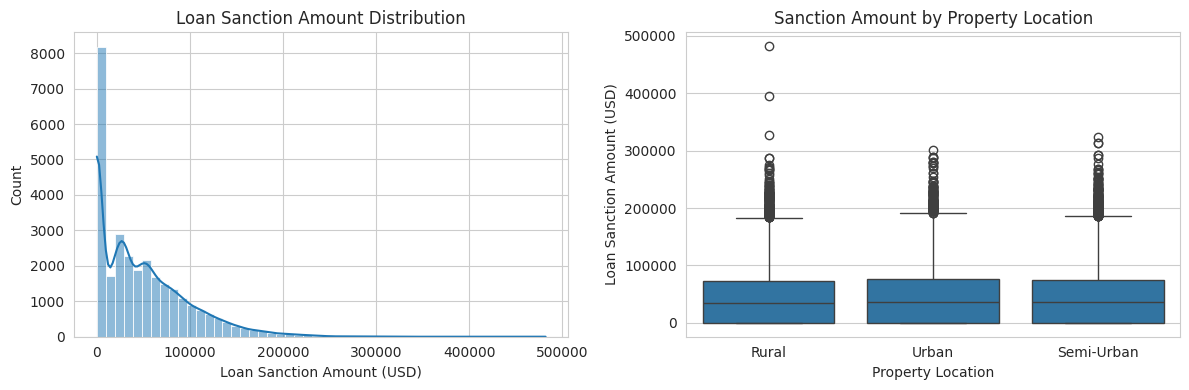

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(loan[target], bins=50, kde=True, ax=axes[0])
axes[0].set_title("Loan Sanction Amount Distribution")
sns.boxplot(data=loan, x="Property Location", y=target, ax=axes[1])
axes[1].set_title("Sanction Amount by Property Location")
plt.tight_layout()
plt.savefig("figures/fig_05_loan_eda.png", dpi=110, bbox_inches="tight")
plt.show()

**Inference:** The target distribution has a large spike at zero and a long right tail up to about 482000,
so it is far from normal. The box plot shows that the median sanctioned amount is nearly the
same across rural, semi-urban and urban properties (about 35000 to 37000), so property
location by itself has little effect on the amount.

In [22]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
X_loan = loan.drop(columns=[target])
y_loan = loan[target]
num_cols = X_loan.select_dtypes("number").columns.tolist()
cat_cols = X_loan.select_dtypes(exclude="number").columns.tolist()
print("Numeric   :", num_cols)
print("Categorical:", cat_cols)
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cols),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("ohe", OneHotEncoder(drop="first", handle_unknown="ignore"))]), cat_cols),
])
Xtr, Xte, ytr, yte = train_test_split(X_loan, y_loan, test_size=0.2, random_state=42)
print("Train / Test:", Xtr.shape, Xte.shape)
reg = Pipeline([("prep", preprocess), ("lr", LinearRegression())]).fit(Xtr, ytr)
pred = reg.predict(Xte)
print("MAE :", round(mean_absolute_error(yte, pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(yte, pred)), 2))
print("R2  :", round(r2_score(yte, pred), 4))

Numeric   : ['Age', 'Income (USD)', 'Loan Amount Request (USD)', 'Current Loan Expenses (USD)', 'Dependents', 'Credit Score', 'No. of Defaults', 'Property Age', 'Property Type', 'Co-Applicant', 'Property Price']
Categorical: ['Gender', 'Income Stability', 'Profession', 'Type of Employment', 'Location', 'Expense Type 1', 'Expense Type 2', 'Has Active Credit Card', 'Property Location']
Train / Test: (23457, 20) (5865, 20)


MAE : 18761.59
RMSE: 27756.26
R2  : 0.6575


**Inference:** A column transformer handled both data types: numeric columns were median-imputed and
standardised, and categorical columns were mode-imputed and one-hot encoded with the first
level dropped. Fitting the imputers and scaler inside a pipeline avoids leakage from the
test split. A plain linear regression reaches an R-squared of 0.658 with a mean absolute
error of about 18762 USD and an RMSE of about 27756 USD on the held-out 20%. The model
explains about two thirds of the variance, and the zero-valued rows are a likely reason why
it cannot do better.

In [23]:
corr = loan[num_cols + [target]].corr()[target].drop(target).sort_values(key=abs, ascending=False)
print("Correlation of numeric features with the target:\n", corr.round(3))

Correlation of numeric features with the target:
 Loan Amount Request (USD)      0.735
Property Price                 0.710
Current Loan Expenses (USD)    0.555
Credit Score                   0.373
Co-Applicant                   0.267
Income (USD)                   0.038
Property Age                   0.038
Dependents                     0.009
Age                            0.007
No. of Defaults               -0.004
Property Type                  0.002
Name: Loan Sanction Amount (USD), dtype: float64


**Inference:** The requested loan amount (r = 0.735), property price (0.710) and current loan expenses
(0.555) have the strongest linear relationship with the sanctioned amount, followed by
credit score (0.373). Income, property age, dependents, age and the number of defaults are
close to zero. For a regression target, correlation-based selection is therefore the natural
choice, because ANOVA and chi-square need a categorical target.

## Predicting Diabetes: Classification (Supervised)



The scikit-learn diabetes dataset records a continuous disease-progression score. It is
binarised around the median to frame the classic diabetes-risk classification task (as in
the Pima Indians dataset).

In [24]:
from sklearn.datasets import load_diabetes
diab = load_diabetes(as_frame=True)
diab_df = diab.frame.copy()
diab_df["Diabetic"] = (diab_df["target"] > diab_df["target"].median()).astype(int)
print(diab_df.head())
print("\nShape:", diab_df.shape)
print("\nClass balance:\n", diab_df["Diabetic"].value_counts())

        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  Diabetic  
0 -0.002592  0.019907 -0.017646   151.0         1  
1 -0.039493 -0.068332 -0.092204    75.0         0  
2 -0.002592  0.002861 -0.025930   141.0         1  
3  0.034309  0.022688 -0.009362   206.0         1  
4 -0.002592 -0.031988 -0.046641   135.0         0  

Shape: (442, 12)

Class balance:
 Diabetic
1    221
0    221
Name: count, dtype: int64


**Inference:** The diabetes data has 442 patients and 10 standardised features. Splitting the progression
score at its median gives two perfectly balanced classes (221 each), so accuracy is a fair
metric and no resampling is needed.

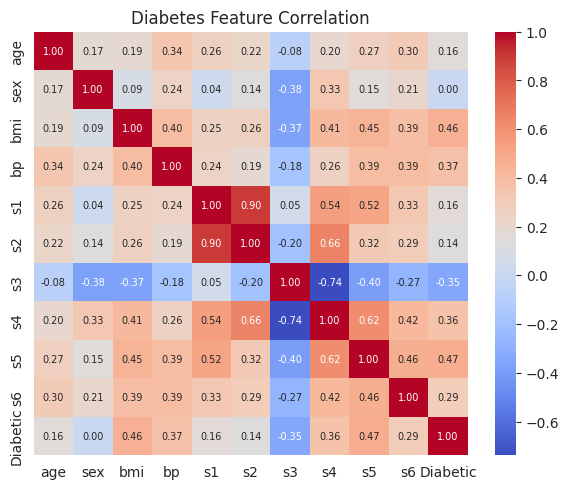

In [25]:
plt.figure(figsize=(7, 5.5))
sns.heatmap(diab_df.drop(columns=["target"]).corr(), cmap="coolwarm", annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Diabetes Feature Correlation")
plt.savefig("figures/fig_06_diab_corr.png", dpi=110, bbox_inches="tight")
plt.show()

**Inference:** The serum measurements s1 and s2 are almost collinear (0.90), and s4 is strongly related to
s2 (0.66), s5 (0.62) and negatively to s3 (-0.74), while BMI correlates moderately with most
other variables (0.25 to 0.45). This multicollinearity makes the individual coefficients of
a plain linear model unstable, which is one reason a tree-based model is used here.

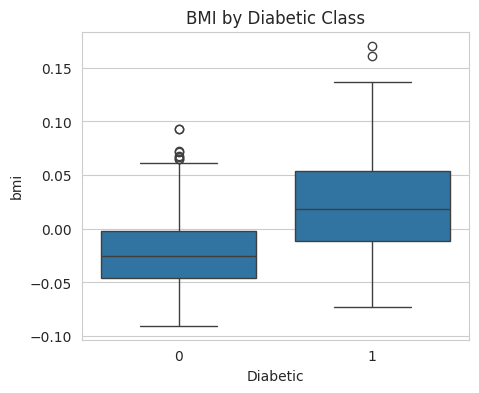

In [26]:
plt.figure(figsize=(5, 4))
sns.boxplot(data=diab_df, x="Diabetic", y="bmi")
plt.title("BMI by Diabetic Class")
plt.savefig("figures/fig_07_diab_box.png", dpi=110, bbox_inches="tight")
plt.show()

**Inference:** The median (standardised) BMI is about 0.02 for the high-progression class and about -0.03
for the low-progression class, and the interquartile ranges barely overlap (the 75th
percentile of the low class is -0.002 and the 25th percentile of the high class is -0.012),
so BMI is a useful predictor of disease progression.

In [27]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
X_d = diab_df.drop(columns=["target", "Diabetic"])
y_d = diab_df["Diabetic"]
X_d_pos = MinMaxScaler().fit_transform(X_d)
chi_scores, chi_p = chi2(X_d_pos, y_d)
print("Chi2 scores:\n", pd.Series(chi_scores, index=X_d.columns).sort_values(ascending=False).round(3))
Xtr, Xte, ytr, yte = train_test_split(X_d, y_d, test_size=0.2, random_state=42, stratify=y_d)
clf = RandomForestClassifier(random_state=42).fit(Xtr, ytr)
pred = clf.predict(Xte)
print("\nAccuracy:", round(accuracy_score(yte, pred), 4))
print(classification_report(yte, pred))

Chi2 scores:
 bmi    9.011
s5     6.868
s4     6.314
bp     4.874
s3     4.147
s6     2.236
age    1.065
s1     0.727
s2     0.513
sex    0.005
dtype: float64



Accuracy: 0.764
              precision    recall  f1-score   support

           0       0.82      0.69      0.75        45
           1       0.73      0.84      0.78        44

    accuracy                           0.76        89
   macro avg       0.77      0.76      0.76        89
weighted avg       0.77      0.76      0.76        89



**Inference:** Features were scaled to [0, 1] because the chi-square test needs non-negative inputs. BMI
(9.01), s5 (6.87) and s4 (6.31) score highest, and sex (0.005) is essentially irrelevant. A
random forest reached 76.4% accuracy on 89 test patients, with recall of 0.84 for the high-
progression class and 0.69 for the low-progression class, so it tends to flag too many
patients as high risk.

## Email Spam Classification: Classification (Supervised)

In [28]:
import re
names = [re.match(r"^([\w#;()\[\]!$]+):", l).group(1) for l in open("data/spambase.names") if re.match(r"^(word|char|capital)", l)]
names = names + ["is_spam"]
spam_df = pd.read_csv("data/spambase.data", header=None, names=names)
print("Shape:", spam_df.shape)
print("Missing values:", int(spam_df.isna().sum().sum()))
print("\nClass balance:\n", spam_df["is_spam"].value_counts())

Shape: (4601, 58)
Missing values: 0

Class balance:
 is_spam
0    2788
1    1813
Name: count, dtype: int64


**Inference:** Spambase has 4601 emails and 57 numeric features, such as word and character frequencies and
capital-letter run lengths, with no missing values. The classes are moderately imbalanced:
2788 ham (60.6%) and 1813 spam (39.4%). This is a supervised binary classification task.

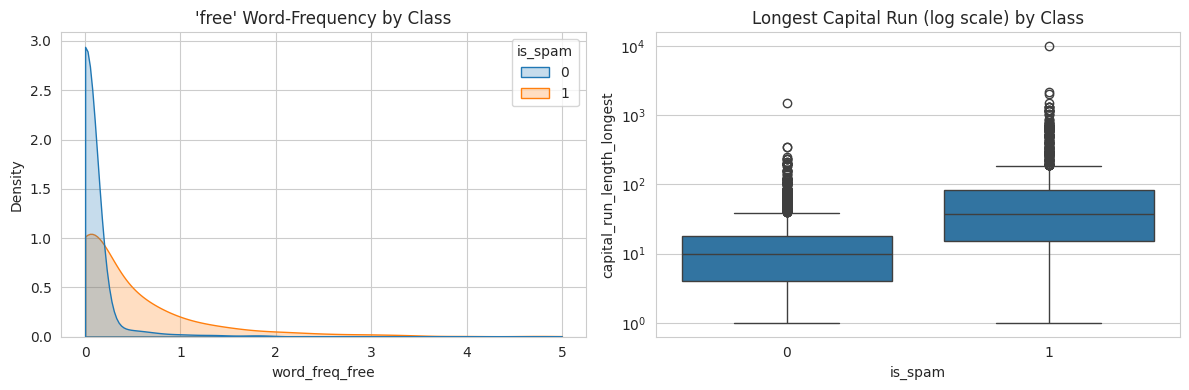

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.kdeplot(data=spam_df, x="word_freq_free", hue="is_spam", fill=True, common_norm=False, clip=(0, 5), ax=axes[0])
axes[0].set_title("'free' Word-Frequency by Class")
sns.boxplot(data=spam_df, x="is_spam", y="capital_run_length_longest", ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Longest Capital Run (log scale) by Class")
plt.tight_layout()
plt.savefig("figures/fig_08_spam_eda.png", dpi=110, bbox_inches="tight")
plt.show()

**Inference:** Spam emails use the word 'free' much more often than ham, whose distribution is concentrated
near zero. The longest run of capital letters is also much larger for spam (median 38
against 10 for ham), so a log scale is needed to see both classes. Both features are clearly
discriminative.

In [30]:
from sklearn.naive_bayes import GaussianNB
X_s = spam_df.drop(columns=["is_spam"])
y_s = spam_df["is_spam"]
f_scores, _ = f_classif(X_s, y_s)
print("Top 8 ANOVA F-scores:\n", pd.Series(f_scores, index=X_s.columns).sort_values(ascending=False).head(8).round(1))
Xtr, Xte, ytr, yte = train_test_split(X_s, y_s, test_size=0.2, random_state=42, stratify=y_s)
sc = StandardScaler().fit(Xtr)
Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte)
clf = GaussianNB().fit(Xtr_s, ytr)
pred = clf.predict(Xte_s)
print("\nAccuracy:", round(accuracy_score(yte, pred), 4))
print(classification_report(yte, pred, target_names=["ham", "spam"]))

Top 8 ANOVA F-scores:
 word_freq_your        791.7
word_freq_000         580.5
word_freq_remove      570.2
char_freq_$           538.0
word_freq_you         372.3
word_freq_free        342.3
word_freq_business    342.3
word_freq_hp          324.5
dtype: float64

Accuracy: 0.8328
              precision    recall  f1-score   support

         ham       0.97      0.75      0.84       558
        spam       0.71      0.96      0.82       363

    accuracy                           0.83       921
   macro avg       0.84      0.85      0.83       921
weighted avg       0.87      0.83      0.83       921



**Inference:** The ANOVA F-test ranks 'your' (791.7), '000' (580.5), 'remove' (570.2) and the dollar sign
(538.0) highest, which are typical spam markers. A Gaussian naive Bayes baseline trained on
standardised features reaches 83.3% accuracy. Its recall for spam is high (0.96) but its
precision is lower (0.71), so it misclassifies many legitimate emails as spam (ham recall
0.75). For a spam filter that is costly, which suggests trying logistic regression or an
SVM, as in later experiments.

## Handwritten Character Recognition (MNIST-style): Classification (Supervised)

Data shape: (1797, 64) | Image shape: (8, 8)
Classes: [0 1 2 3 4 5 6 7 8 9]


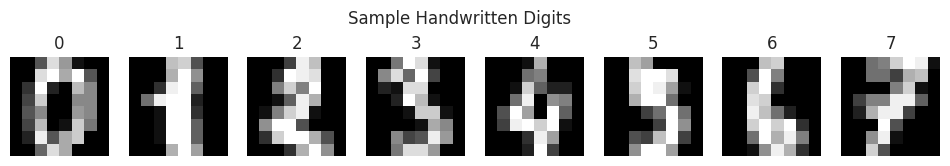

In [31]:
from sklearn.datasets import load_digits
digits = load_digits()
print("Data shape:", digits.data.shape, "| Image shape:", digits.images[0].shape)
print("Classes:", np.unique(digits.target))
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i, ax in enumerate(axes):
    ax.imshow(digits.images[i], cmap="gray")
    ax.set_title(digits.target[i]); ax.axis("off")
plt.suptitle("Sample Handwritten Digits")
plt.savefig("figures/fig_09_digits_samples.png", dpi=110, bbox_inches="tight")
plt.show()

**Inference:** The digits dataset contains 1797 images of 8x8 pixels (64 features) in 10 classes. Even at
this low resolution the digits are recognisable to the eye, which suggests that the pixel
intensities are informative enough for classical models.

In [32]:
from sklearn.svm import SVC
X_h, y_h = digits.data, digits.target
Xtr, Xte, ytr, yte = train_test_split(X_h, y_h, test_size=0.2, random_state=42, stratify=y_h)
sc = StandardScaler().fit(Xtr)
Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte)
clf = SVC(kernel="rbf", gamma=0.001).fit(Xtr_s, ytr)
pred = clf.predict(Xte_s)
print("Accuracy:", round(accuracy_score(yte, pred), 4))

Accuracy: 0.95


**Inference:** An RBF-kernel SVM on standardised pixel values reaches 95.0% accuracy on the 360 test images
without any tuning of C or gamma.

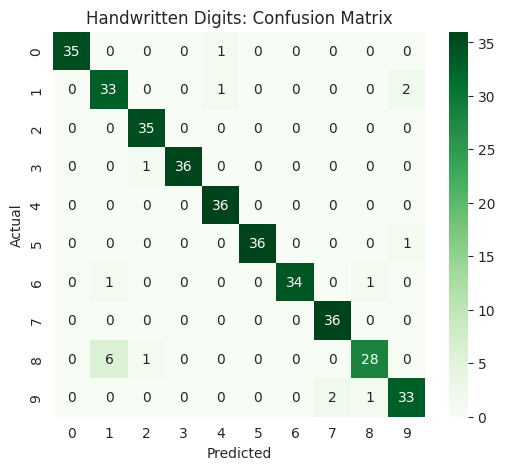

In [33]:
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(yte, pred), annot=True, fmt="d", cmap="Greens")
plt.title("Handwritten Digits: Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.savefig("figures/fig_10_digits_cm.png", dpi=110, bbox_inches="tight")
plt.show()

**Inference:** The diagonal dominates the matrix. The most frequent confusion is digit 8 predicted as 1 (6
cases), followed by 1 predicted as 9 and 9 predicted as 7 (2 cases each). Digits 2, 4 and 7
are classified perfectly. On an 8x8 grid the thin strokes of 1 and the loops of 8 lose
detail, which explains these errors.

# Summary Table




| Dataset | Type of ML Task | Feature Selection Technique | Suitable ML Algorithm |
|---|---|---|---|
| Iris Dataset | Classification (Supervised) | ANOVA F-test (SelectKBest) | Decision Tree / Logistic Regression |
| Loan Amount Prediction | Regression (Supervised) | Correlation / domain-based selection | Linear Regression |
| Predicting Diabetes | Classification (Supervised) | Chi-square test | Random Forest Classifier |
| Classification of Email Spam | Classification (Supervised) | ANOVA F-test (SelectKBest) | Naive Bayes / Logistic Regression |
| Handwritten Character Recognition / MNIST | Classification (Supervised) | Variance / PCA on pixel intensities | SVM / CNN |


**Inference:** The summary table matches each dataset to its task type, a suitable feature selection
technique and a baseline algorithm. ANOVA is used when the features are continuous and the
target is categorical (Iris, Spambase), chi-square needs non-negative features and a
categorical target (Diabetes), and correlation is used for the regression target (Loan). For
image pixels, variance filtering or PCA is the natural way to reduce dimensionality.

# Discussion



NumPy supplies the vectorised array operations, Pandas the labelled tables and missing-value
handling, SciPy the statistical tests and linear algebra, Matplotlib and Seaborn the
exploratory plots, and scikit-learn the common fit/predict/transform interface, so one
workflow (load, explore, preprocess, select features, split, fit, evaluate) was reused for
all five datasets. The choice of task followed the target variable: a continuous target (the
loan amount) gives regression and a discrete one gives classification. The real loan file
showed why preprocessing matters, because it contained missing values in 11 columns and -999
placeholders that had to be converted before modelling. Fitting the imputer, scaler and
encoder inside a pipeline on the training split only prevented information leaking from the
test set. Accuracy ranged from 76.4% on the noisy diabetes problem to 95.0% on the digits,
which shows that baseline performance depends mostly on how separable the data is and not on
the library used.

# Conclusion



The experiment demonstrated the main functions of NumPy, Pandas, SciPy, Scikit-learn and
Matplotlib and applied the full machine learning workflow to five datasets. Iris (93.3% with
a depth-3 tree), diabetes (76.4% with a random forest), Spambase (83.3% with Gaussian naive
Bayes) and the handwritten digits (95.0% with an RBF SVM) were treated as classification
problems, and loan amount prediction as a regression problem (R-squared 0.658 with linear
regression). For each dataset an appropriate feature selection technique and baseline
algorithm were identified and tabulated. These baselines are the starting point for the
tuned models studied in the following experiments.

# References



[1] C. R. Harris et al., "Array programming with NumPy," Nature, vol. 585, pp. 357-362, 2020.

[2] W. McKinney, "Data structures for statistical computing in Python," in Proc. 9th Python in Science Conf., 2010, pp. 56-61.

[3] P. Virtanen et al., "SciPy 1.0: fundamental algorithms for scientific computing in Python," Nature Methods, vol. 17, pp. 261-272, 2020.

[4] F. Pedregosa et al., "Scikit-learn: Machine learning in Python," J. Mach. Learn. Res., vol. 12, pp. 2825-2830, 2011.

[5] J. D. Hunter, "Matplotlib: A 2D graphics environment," Computing in Science & Engineering, vol. 9, no. 3, pp. 90-95, 2007.

[6] UCI Machine Learning Repository, Spambase Data Set. [Online]. Available: https://archive.ics.uci.edu/dataset/94/spambase

[7] Predict Loan Amount Data, Kaggle. [Online]. Available: https://www.kaggle.com/